# Lab 2. NumPy and pandas — Airports / Аэропорты

**Variant / Вариант:** the same airports as Lab 1; `X = elevation_ft`, `G = kind`.
**Вариант:** тот же набор аэропортов, что в ЛР1; X — высота в футах, G — тип аэропорта.

Run in **JupyterLab**: from the repository root run `.venv\Scripts\python -m jupyterlab`,
open `lab2/analysis.ipynb`, then choose **Kernel → Restart Kernel and Run All Cells**.
Запустите JupyterLab из корня проекта, откройте блокнот и выполните все ячейки после перезапуска ядра.
The saved outputs are actual computations. / Сохранённые результаты получены выполнением кода.

Each experiment below uses the original table unless explicitly stated otherwise.
Каждый эксперимент использует исходную таблицу, если явно не указано другое.

## 1. Preparation / Подготовка

A fixed seed reproduces selections when all cells run in order. NumPy randomness uses `rng`.
Фиксированный seed воспроизводит выборки при последовательном запуске всех ячеек. Случайные выборки NumPy используют `rng`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

SEED = 42
rng = np.random.default_rng(SEED)
X, G = "elevation_ft", "kind"
ROOT = Path.cwd().resolve()
if not (ROOT / "lab1").is_dir():
    ROOT = ROOT.parent
DATA = ROOT / "lab1" / "data" / "airports" / "records.csv"
OUT = ROOT / "lab2" / "results"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 15)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.2})
print("Seed:", SEED, "| Data:", DATA.name)

Seed: 42 | Data: records.csv


## 2. Loading / Загрузка

The bundled CSV is the dataset already used in Lab 1, so another download is unnecessary.
`to_numeric(errors="coerce")` converts invalid numeric text to missing values, never zero.
Blank groups are named `Неизвестно` before grouping; missing heights remain missing.

CSV уже находится в проекте после ЛР1. `to_numeric(errors="coerce")` превращает некорректные числа в пропуски,
а не в нули. Пустые типы получают группу `Неизвестно`; высоты с пропусками не заменяются.

**EN:** Explicit missing markers preserve the country code `NA` (Namibia), which pandas would otherwise interpret as missing.

**RU:** Явные маркеры пропусков сохраняют код страны `NA` (Намибия), который pandas иначе считал бы пропуском.

In [2]:
df = pd.read_csv(DATA, keep_default_na=False, na_values=["", "null", "NULL"])
df[X] = pd.to_numeric(df[X], errors="coerce")
# Treat whitespace-only group names as missing as well.
df[G] = df[G].astype("string").str.strip().replace("", pd.NA).fillna("Неизвестно")
original = df.copy(deep=True)
assert pd.api.types.is_numeric_dtype(df[X])
print(f"Rows / Строки: {len(df)}; missing X / пропуски X: {df[X].isna().sum()}")
display(df.head(5))

Rows / Строки: 8000; missing X / пропуски X: 1450


,id,title,city,keywords,country,kind,elevation_ft,latitude,longitude,scheduled,url
0,US-6265,Chickasaw Nation Medical Center Heliport,Ada,NaN,US,heliport,815.0,34.730033,-96.643508,False,https://ourairports.com/airports/US-6265/
1,LIPR,Federico Fellini International Airport,Rimini (RN),"Rimini Miramare Airport, Rimini San Marino Int...",IT,large_airport,40.0,44.020024,12.612198,True,https://ourairports.com/airports/LIPR/
2,KJKJ,Moorhead Municipal Airport,Moorhead,NaN,US,small_airport,918.0,46.839170,-96.663703,False,https://ourairports.com/airports/KJKJ/
3,US-3794,Three Rivers Airport (1935),Three Rivers,NaN,US,closed,NaN,36.475260,-118.921310,False,https://ourairports.com/airports/US-3794/
4,ID-0194,Korowai Batu Danowage Airport,Danowage,NaN,ID,small_airport,340.0,-5.212700,140.017582,False,https://ourairports.com/airports/ID-0194/


## 3. Missing values / Пропуски

Hide 10% of observed heights and save the original values only for evaluation.
All three methods see the **same** damaged table. The third method is the median within `kind`,
with the observed global median as fallback for a group without observed heights.
The statistics are computed **after** removal, preventing leakage of hidden answers.

Скрываем 10% известных высот. Все три способа получают одинаковые пропуски.
Третий способ — медиана по типу аэропорта; если в группе нет известных высот, используется общая медиана.
Все значения для заполнения считаются **после** удаления. Сохранённые ответы используются только для проверки.

MAE has units of feet; MSE has units of squared feet and penalizes large errors more strongly.
MAE измеряется в футах, MSE — в квадратных футах; большие ошибки сильнее влияют на MSE.

In [3]:
observed_indices = df.index[df[X].notna()].to_numpy()
hidden_indices = rng.choice(
    observed_indices, size=round(0.10 * len(observed_indices)), replace=False
)
truth = df.loc[hidden_indices, X].copy()
damaged = df.copy(deep=True)
damaged.loc[hidden_indices, X] = np.nan
observed_mean = damaged[X].mean()
observed_median = damaged[X].median()
fill_values = {
    "mean / среднее": observed_mean,
    "median / медиана": observed_median,
    "group median / медиана группы": damaged.groupby(G)[X]
    .transform("median")
    .fillna(observed_median),
}
imputed = {}
errors = []
for method, fill in fill_values.items():
    restored = damaged.copy(deep=True)
    restored[X] = restored[X].fillna(fill)
    imputed[method] = restored
    difference = restored.loc[hidden_indices, X].to_numpy() - truth.to_numpy()
    errors.append(
        {
            "method": method,
            "MAE_ft": np.mean(np.abs(difference)),
            "MSE_ft2": np.mean(difference**2),
        }
    )
    np.testing.assert_array_equal(
        restored.loc[damaged[X].notna(), X], damaged.loc[damaged[X].notna(), X]
    )
error_table = pd.DataFrame(errors).set_index("method")
print(f"Hidden known values / Скрыто известных значений: {len(truth)}")
print(f"Observed mean / Среднее после удаления: {observed_mean:.3f}")
print(f"Observed median / Медиана после удаления: {observed_median:.3f}")
display(error_table)
display(pd.DataFrame({"index": hidden_indices[:5], "true_X": truth.to_numpy()[:5]}))
print("Best MAE / Минимум MAE:", error_table["MAE_ft"].idxmin())
print("Best MSE / Минимум MSE:", error_table["MSE_ft2"].idxmin())

Hidden known values / Скрыто известных значений: 655
Observed mean / Среднее после удаления: 1309.477
Observed median / Медиана после удаления: 731.000


,MAE_ft,MSE_ft2
method,,
mean / среднее,1136.778616,2.595471e+06
median / медиана,993.728244,2.847967e+06
group median / медиана группы,981.191603,2.866266e+06


,index,true_X
0,1331,1870.0
1,2254,10.0
2,1980,4300.0
3,2922,141.0
4,6917,10961.0


Best MAE / Минимум MAE: group median / медиана группы
Best MSE / Минимум MSE: mean / среднее


The sample mean minimizes squared error for a single constant on that sample; the median minimizes absolute error.
Here the filling constants come from the remaining observations, while evaluation uses a different, hidden subset,
so an exact ranking is empirical. Elevation has a long upper tail: a few large mistakes can dominate MSE.
Group medians use airport type but cannot recover the geography of each individual airport.

Среднее минимизирует квадраты ошибок при заполнении одной константой на той же выборке, медиана — модули ошибок.
Здесь константы считаются по оставшимся данным, а проверка идёт по скрытой выборке, поэтому победителя определяет эксперимент.
У высоты длинный правый хвост: несколько больших ошибок могут определять MSE. Медиана группы учитывает тип,
но не восстанавливает географию отдельного аэропорта.

## 4. Duplicates / Дубликаты

Append exact copies of 5% of the **original** rows. Apply the three removal methods independently.
The chosen third field is `country`: it intentionally demonstrates an overly broad key.
Airports in the same country are different objects, so dropping by country loses real data.

Добавляем точные копии 5% **исходных** строк. Три способа применяются независимо.
Третье поле — `country`: это намеренно слишком широкий ключ. Разные аэропорты одной страны не являются дубликатами.

In [4]:
duplicate_indices = rng.choice(
    df.index.to_numpy(), size=round(0.05 * len(df)), replace=False
)
with_duplicates = pd.concat(
    [df.copy(deep=True), df.loc[duplicate_indices].copy()], ignore_index=True
)
deduplicated = {
    "all columns / все поля": with_duplicates.copy().drop_duplicates(),
    "id": with_duplicates.copy().drop_duplicates(subset="id"),
    "country / страна": with_duplicates.copy().drop_duplicates(subset="country"),
}
stages = {
    "before / до": df,
    "after adding / после добавления": with_duplicates,
    **deduplicated,
}
duplicate_table = pd.DataFrame(
    [
        {"stage": name, "rows": len(table), "mean_X_ft": table[X].mean()}
        for name, table in stages.items()
    ]
).set_index("stage")
display(duplicate_table)
country_id_counts = df.groupby("country", dropna=False)["id"].nunique()
shared_countries = country_id_counts[country_id_counts > 1].index
examples = df[df["country"].isin(shared_countries)].sort_values(["country", "id"])
if examples.empty:
    print("No shared country with distinct IDs / Совпадений страны с разными id нет.")
else:
    example_country = examples.iloc[0]["country"]
    display(
        df[df["country"].eq(example_country)].head(5)[["id", "title", "country", X]]
    )
print(
    "Original exact duplicate rows / Исходных полных повторов:", df.duplicated().sum()
)
print("Original duplicate IDs / Исходных повторов id:", df.duplicated("id").sum())
assert len(with_duplicates) == len(df) + len(duplicate_indices)

,rows,mean_X_ft
stage,,
before / до,8000,1302.377252
after adding / после добавления,8400,1301.262081
all columns / все поля,8000,1302.377252
id,8000,1302.377252
country / страна,193,1225.959732


,id,title,country,elevation_ft
38,AE-0056,Al Ferasa Tower Helipad,AE,NaN
90,AE-0057,Golden Tower Helipad,AE,NaN
606,OMDB,Dubai International Airport,AE,62.0
612,AE-0091,Lower Yasat Island Airport,AE,NaN
1096,AE-0009,Delma Hospital Helipad,AE,17.0


Original exact duplicate rows / Исходных полных повторов: 0
Original duplicate IDs / Исходных повторов id: 0


Copying a random subset can change the mean because the copied subset need not have the global mean.
Full-row and ID deduplication agree if IDs are unique and no original duplicates exist.
The country method changes both row count and the meaning of the sample: it retains just one airport per country.

Случайное копирование может изменить среднее: среднее скопированных строк не обязано совпадать с общим.
Удаление по всем полям и по id совпадает при уникальных исходных id и отсутствии исходных повторов.
Удаление по стране меняет смысл выборки: остаётся только один аэропорт каждой страны.

## 5. Numerical statistics / Числовые характеристики

Manual computation below uses sorting, loops and arithmetic, without ready-made statistical functions.
Population variance divides by N; NumPy and pandas comparisons explicitly use `ddof=0`.
Default pandas variance uses N−1 and therefore would describe a different quantity.

Ручной расчёт использует сортировку, циклы и арифметику без готовых статистических функций.
Дисперсия делится на N; для сравнения явно указано `ddof=0`. По умолчанию pandas делит на N−1.

In [5]:
values = df[X].dropna().to_numpy()
ordered = sorted(float(v) for v in values)
n = len(ordered)
assert n > 0
total = 0.0
for value in ordered:
    total += value
manual_mean = total / n
middle = n // 2
manual_median = (
    ordered[middle] if n % 2 else (ordered[middle - 1] + ordered[middle]) / 2
)
squared_deviations = 0.0
for value in ordered:
    squared_deviations += (value - manual_mean) ** 2
manual_variance = squared_deviations / n
manual = [
    ordered[-1] - ordered[0],
    manual_mean,
    manual_median,
    manual_variance,
    manual_variance**0.5,
]
numpy_stats = [
    np.ptp(values),
    np.mean(values),
    np.median(values),
    np.var(values, ddof=0),
    np.std(values, ddof=0),
]
pandas_stats = [
    df[X].max() - df[X].min(),
    df[X].mean(),
    df[X].median(),
    df[X].var(ddof=0),
    df[X].std(ddof=0),
]
statistics = pd.DataFrame(
    {"manual": manual, "NumPy": numpy_stats, "pandas": pandas_stats},
    index=["range", "mean", "median", "variance_ddof0", "std_ddof0"],
)
np.testing.assert_allclose(manual, numpy_stats, rtol=1e-12)
np.testing.assert_allclose(manual, pandas_stats, rtol=1e-12)
display(statistics)

,manual,NumPy,pandas
range,1.518700e+04,1.518700e+04,1.518700e+04
mean,1.302377e+03,1.302377e+03,1.302377e+03
median,7.300000e+02,7.300000e+02,7.300000e+02
variance_ddof0,2.755657e+06,2.755657e+06,2.755657e+06
std_ddof0,1.660017e+03,1.660017e+03,1.660017e+03


## 6. Filtering: AND versus OR / Фильтрация: И и ИЛИ

Select `small_airport` and `medium_airport`; compare height to 500 feet.
A missing height does not satisfy the height condition. OR can still include such a row through its group.

Выбираем `small_airport` и `medium_airport`, граница — 500 футов.
Пропуск высоты не проходит условие высоты. Условие ИЛИ может включить эту строку по группе.

In [6]:
selected_groups = ["small_airport", "medium_airport"]
threshold = 500
in_group = df[G].isin(selected_groups)
above = df[X].gt(threshold).fillna(False)
assert above.any() and (df[X].notna() & ~above).any()
and_mask = in_group & above
or_mask = in_group | above
and_table = df.loc[and_mask]
or_table = df.loc[or_mask]
only_or = df.loc[or_mask & ~and_mask]
assert set(and_table.index).issubset(or_table.index)
print(
    f"AND / И: {len(and_table)}; OR / ИЛИ: {len(or_table)}; only OR / только ИЛИ: {len(only_or)}"
)
display(and_table.head())
display(or_table.head())
display(only_or.head(10))

AND / И: 2456; OR / ИЛИ: 5814; only OR / только ИЛИ: 3358


,id,title,city,keywords,country,kind,elevation_ft,latitude,longitude,scheduled,url
2,KJKJ,Moorhead Municipal Airport,Moorhead,NaN,US,small_airport,918.0,46.839170,-96.663703,False,https://ourairports.com/airports/KJKJ/
9,6F1,Talihina Municipal Airport,Talihina,NaN,US,small_airport,687.0,34.707802,-95.073799,False,https://ourairports.com/airports/6F1/
13,OR53,Wapinitia Airport,Wapinitia,NaN,US,small_airport,1910.0,45.145699,-121.228996,False,https://ourairports.com/airports/OR53/
14,SNDV,Brigadeiro Cabral Airport,Divinópolis,NaN,BR,small_airport,2608.0,-20.180700,-44.870899,False,https://ourairports.com/airports/SNDV/
16,GB-0032,Bath Wilts & North Dorset Gliding Club,"Warminster, Wiltshire",Kingston Deverill,GB,small_airport,692.0,51.128899,-2.246017,False,https://ourairports.com/airports/GB-0032/


,id,title,city,keywords,country,kind,elevation_ft,latitude,longitude,scheduled,url
0,US-6265,Chickasaw Nation Medical Center Heliport,Ada,NaN,US,heliport,815.0,34.730033,-96.643508,False,https://ourairports.com/airports/US-6265/
2,KJKJ,Moorhead Municipal Airport,Moorhead,NaN,US,small_airport,918.0,46.839170,-96.663703,False,https://ourairports.com/airports/KJKJ/
4,ID-0194,Korowai Batu Danowage Airport,Danowage,NaN,ID,small_airport,340.0,-5.212700,140.017582,False,https://ourairports.com/airports/ID-0194/
5,AL-0014,Korçë Airfield,Qendër Bulgarec,"LAKO, Korçë Northwest, Lumalas",AL,closed,665.0,40.649879,20.741211,False,https://ourairports.com/airports/AL-0014/
6,DE-0526,Nürburgring Heliport,Nürburg,NaN,DE,heliport,2021.0,50.331241,6.943107,False,https://ourairports.com/airports/DE-0526/


,id,title,city,keywords,country,kind,elevation_ft,latitude,longitude,scheduled,url
0,US-6265,Chickasaw Nation Medical Center Heliport,Ada,NaN,US,heliport,815.0,34.730033,-96.643508,False,https://ourairports.com/airports/US-6265/
4,ID-0194,Korowai Batu Danowage Airport,Danowage,NaN,ID,small_airport,340.0,-5.212700,140.017582,False,https://ourairports.com/airports/ID-0194/
5,AL-0014,Korçë Airfield,Qendër Bulgarec,"LAKO, Korçë Northwest, Lumalas",AL,closed,665.0,40.649879,20.741211,False,https://ourairports.com/airports/AL-0014/
6,DE-0526,Nürburgring Heliport,Nürburg,NaN,DE,heliport,2021.0,50.331241,6.943107,False,https://ourairports.com/airports/DE-0526/
7,K66Y,Diamondhead Airport,Diamondhead,NaN,US,small_airport,14.0,30.363001,-89.387703,False,https://ourairports.com/airports/K66Y/
10,SCAZ,Azopardo Airport,Timaukel,NaN,CL,small_airport,59.0,-54.481014,-68.940689,False,https://ourairports.com/airports/SCAZ/
11,US-10931,Sacatar Meadows Airport,Inyokern,91CL,US,closed,6427.0,35.989899,-118.080002,False,https://ourairports.com/airports/US-10931/
15,64OK,Cordell Memorial Hospital Heliport,Cordell,NaN,US,heliport,1564.0,35.302260,-98.988590,False,https://ourairports.com/airports/64OK/
17,SBJE,Comandante Ariston Pessoa Airport,Cruz,"SSVV, Jericoacoara",BR,medium_airport,89.0,-2.906425,-40.357338,True,https://ourairports.com/airports/SBJE/
18,RU-0941,Gora Airstrip UL,Gora,"Yegoryevsky, Егoрьевск",RU,small_airport,NaN,55.276930,39.251630,False,https://ourairports.com/airports/RU-0941/


## 7. Order of operations / Порядок операций

Filtering first gives the five highest eligible airports. Taking five globally first can discard eligible rows
before the filter has a chance to consider them. These operations do not commute in general.

Сначала фильтрация — затем пять максимальных: получаем лучшие подходящие строки.
Сначала пять максимальных во всей таблице: подходящие строки могут быть отброшены ещё до фильтра.
В общем случае эти операции не перестановочны.

In [7]:
filter_then_top = df.loc[and_mask].nlargest(5, X)
global_top = df.nlargest(5, X)
top_then_filter = global_top.loc[and_mask.reindex(global_top.index)]
print("Filter → top 5 / Фильтр → top 5")
display(filter_then_top[["id", "title", G, X]])
print("Global top 5 → filter / Общий top 5 → фильтр")
display(top_then_filter[["id", "title", G, X]])
same_top_ids = filter_then_top["id"].tolist() == top_then_filter["id"].tolist()
print("Same ordered IDs / Совпадают id и порядок:", same_top_ids)
print(
    "Eligible in global top 5 / Подходящих в общем top 5:",
    int(and_mask.loc[global_top.index].sum()),
)

Filter → top 5 / Фильтр → top 5


,id,title,kind,elevation_ft
5161,SPNP,Ventilla Airport,small_airport,13123.0
1949,PE-0019,Tamburco Airport,small_airport,13002.0
4147,SLPO,Capitan Nicolas Rojas Airport,medium_airport,12922.0
7491,SAOL,La Quiaca Airport,small_airport,11414.0
4576,IT-0780,Rutor Glacier Altiport,small_airport,10830.0


Global top 5 → filter / Общий top 5 → фильтр


,id,title,kind,elevation_ft
5161,SPNP,Ventilla Airport,small_airport,13123.0
1949,PE-0019,Tamburco Airport,small_airport,13002.0
4147,SLPO,Capitan Nicolas Rojas Airport,medium_airport,12922.0


Same ordered IDs / Совпадают id и порядок: False
Eligible in global top 5 / Подходящих в общем top 5: 3


## 8. Grouping / Группировка

Count rows with `size`, not `count(X)`: objects with missing heights must still count.
Means and medians skip missing X; group shares use the complete row count as denominator.

Для количества строк используем `size`, а не `count(X)`: объект с пропуском высоты тоже учитывается.
Средние и медианы игнорируют пропуски X; доля считается от всех строк таблицы.

,group_count,share,missing_X,group_mean,group_median
kind,,,,,
small_airport,3949,0.493625,480,1354.516575,830.0
heliport,2194,0.274250,659,1307.065147,598.0
closed,1274,0.159250,270,1275.120518,689.5
medium_airport,364,0.045500,18,1079.696532,458.0
large_airport,113,0.014125,0,922.681416,140.0
seaplane_base,100,0.012500,23,699.376623,580.0
balloonport,6,0.000750,0,2249.500000,940.0


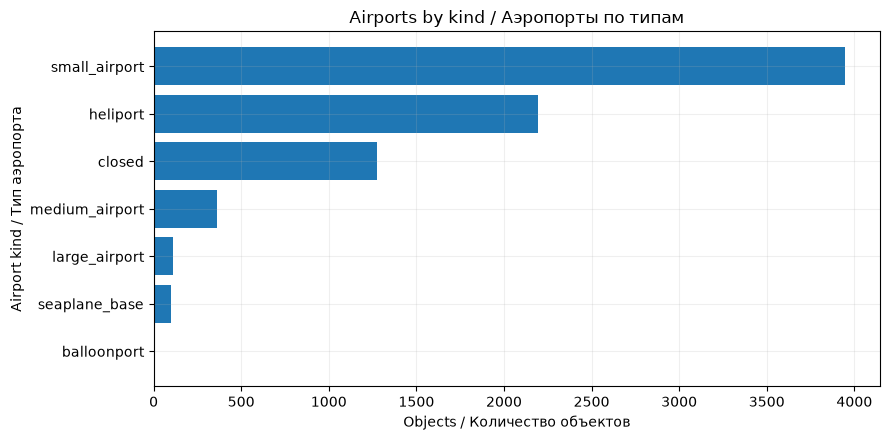

Most / Больше всего: small_airport 3949
Fewest / Меньше всего: balloonport 6


In [8]:
grouped = df.groupby(G, dropna=False)[X]
group_stats = grouped.agg(
    group_count="size",
    missing_X=lambda s: s.isna().sum(),
    group_mean="mean",
    group_median="median",
)
group_stats["share"] = group_stats["group_count"] / len(df)
group_stats = group_stats[
    ["group_count", "share", "missing_X", "group_mean", "group_median"]
]
group_stats = group_stats.sort_values("group_count", ascending=False)
assert group_stats["group_count"].sum() == len(df)
assert np.isclose(group_stats["share"].sum(), 1)
display(group_stats)
fig, ax = plt.subplots()
ax.barh(group_stats.index.astype(str), group_stats["group_count"])
ax.invert_yaxis()
ax.set(
    xlabel="Objects / Количество объектов",
    ylabel="Airport kind / Тип аэропорта",
    title="Airports by kind / Аэропорты по типам",
)
fig.tight_layout()
fig.savefig(OUT / "group_counts.png", dpi=150)
plt.show()
print(
    "Most / Больше всего:",
    group_stats.index[0],
    int(group_stats.iloc[0]["group_count"]),
)
print(
    "Fewest / Меньше всего:",
    group_stats.index[-1],
    int(group_stats.iloc[-1]["group_count"]),
)

## 9. An object and its group / Объект и его группа

A validated many-to-one join adds exactly one summary row per original object.
`delta = X - group_mean`; a missing X produces a missing delta.
Use the **same first 100 observed objects** for both plots; sorting changes their order, not their membership.

Соединение many-to-one добавляет каждой строке ровно одну сводку её группы.
`delta = X - group_mean`; пропуск X даёт пропуск delta.
Оба графика используют **одни и те же первые 100 объектов с известным X**; сортировка меняет только порядок.

,id,title,kind,elevation_ft,group_count,group_mean,delta
0,US-6265,Chickasaw Nation Medical Center Heliport,heliport,815.0,2194,1307.065147,-492.065147
1,LIPR,Federico Fellini International Airport,large_airport,40.0,113,922.681416,-882.681416
2,KJKJ,Moorhead Municipal Airport,small_airport,918.0,3949,1354.516575,-436.516575
3,US-3794,Three Rivers Airport (1935),closed,NaN,1274,1275.120518,NaN
4,ID-0194,Korowai Batu Danowage Airport,small_airport,340.0,3949,1354.516575,-1014.516575
5,AL-0014,Korçë Airfield,closed,665.0,1274,1275.120518,-610.120518
6,DE-0526,Nürburgring Heliport,heliport,2021.0,2194,1307.065147,713.934853
7,K66Y,Diamondhead Airport,small_airport,14.0,3949,1354.516575,-1340.516575
8,AU-0055,Brooklyn Oval Helicopter Landing Site,heliport,33.0,2194,1307.065147,-1274.065147
9,6F1,Talihina Municipal Airport,small_airport,687.0,3949,1354.516575,-667.516575


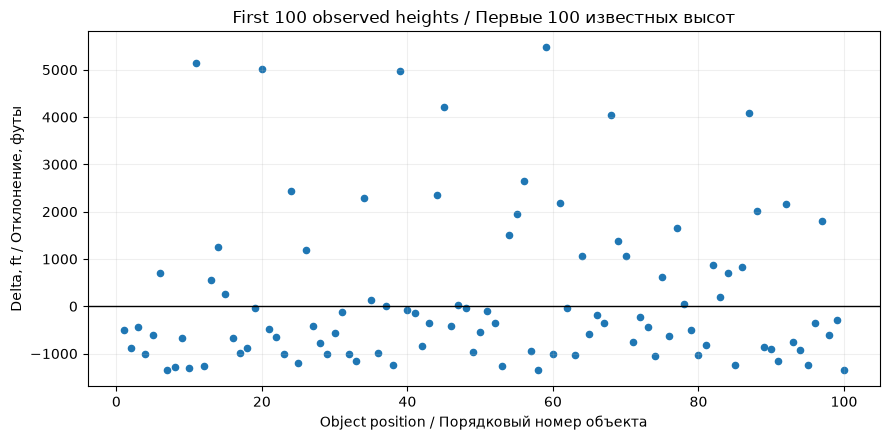

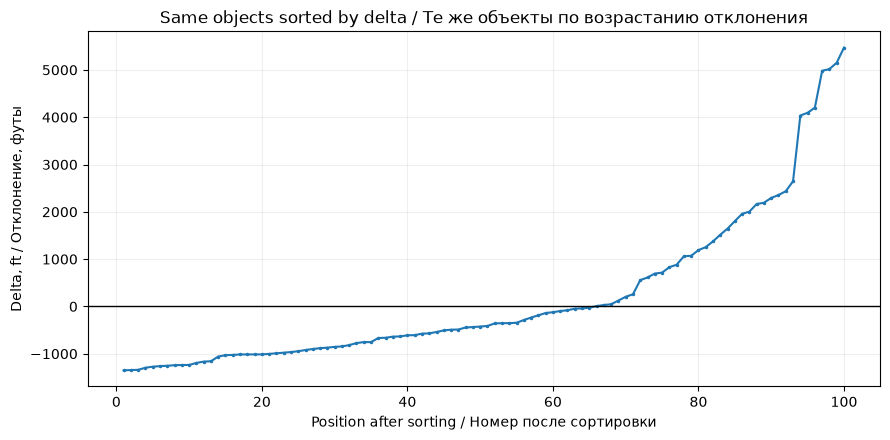

In [9]:
enriched = df.join(
    group_stats[["group_count", "group_mean"]], on=G, validate="many_to_one"
)
enriched["delta"] = enriched[X] - enriched["group_mean"]
assert len(enriched) == len(df)
assert enriched.index.equals(df.index)
display(enriched[["id", "title", G, X, "group_count", "group_mean", "delta"]].head(10))
fragment = enriched.loc[enriched[X].notna()].head(100).copy()
positions = np.arange(1, len(fragment) + 1)
fig, ax = plt.subplots()
ax.scatter(positions, fragment["delta"], s=20)
ax.axhline(0, color="black", linewidth=1)
ax.set(
    xlabel="Object position / Порядковый номер объекта",
    ylabel="Delta, ft / Отклонение, футы",
    title="First 100 observed heights / Первые 100 известных высот",
)
fig.tight_layout()
fig.savefig(OUT / "group_delta_scatter.png", dpi=150)
plt.show()
sorted_fragment = fragment.sort_values("delta", kind="stable")
assert set(fragment.index) == set(sorted_fragment.index)
assert sorted_fragment["delta"].is_monotonic_increasing
fig, ax = plt.subplots()
ax.plot(positions, sorted_fragment["delta"], marker=".", markersize=3)
ax.axhline(0, color="black", linewidth=1)
ax.set(
    xlabel="Position after sorting / Номер после сортировки",
    ylabel="Delta, ft / Отклонение, футы",
    title="Same objects sorted by delta / Те же объекты по возрастанию отклонения",
)
fig.tight_layout()
fig.savefig(OUT / "group_delta_sorted.png", dpi=150)
plt.show()

## 10. Quantiles and boxplot / Квантили и boxplot

Use the five largest groups **by row count**, then omit missing heights inside their boxplots.
The central line is the median, the box spans Q1–Q3, whiskers extend to observations within 1.5 IQR.
Points beyond whiskers are statistical outliers, not automatically invalid data.

Берём пять крупнейших групп **по числу строк**; пропуски высоты не входят в boxplot.
Линия внутри коробки — медиана, коробка — Q1–Q3, усы доходят до наблюдений в пределах 1,5 IQR.
Точки за усами — статистические выбросы, которые не обязательно являются ошибками данных.

,height_ft / высота_футы
0.25,207.25
0.50,730.00
0.75,1630.00


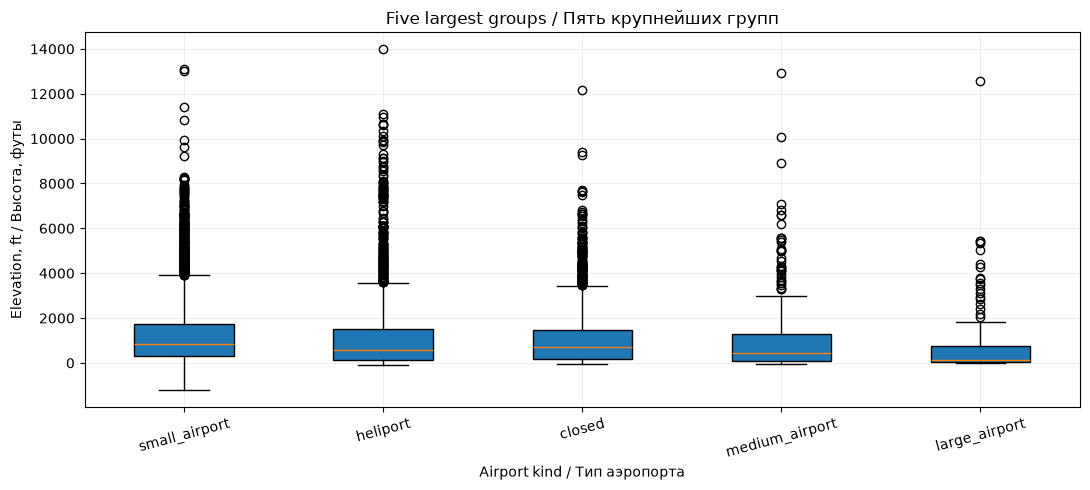

,median,q1,q3,minimum,maximum,IQR,range
kind,,,,,,,
closed,689.5,197.0,1489.00,-59.0,12169.0,1292.00,12228.0
heliport,598.0,140.0,1517.50,-72.0,13980.0,1377.50,14052.0
large_airport,140.0,39.0,755.00,5.0,12552.0,716.00,12547.0
medium_airport,458.0,84.0,1303.75,-70.0,12922.0,1219.75,12992.0
small_airport,830.0,308.0,1750.00,-1207.0,13123.0,1442.00,14330.0


Highest median / Наибольшая медиана: small_airport
Largest IQR / Наибольший IQR: small_airport
Largest range / Наибольший размах: small_airport


In [10]:
quantiles = df[X].quantile([0.25, 0.5, 0.75])
display(quantiles.rename("height_ft / высота_футы").to_frame())
top_groups = group_stats.head(5).index.tolist()
box_data = [df.loc[df[G].eq(group), X].dropna().to_numpy() for group in top_groups]
fig, ax = plt.subplots(figsize=(11, 5))
ax.boxplot(box_data, tick_labels=top_groups, patch_artist=True)
ax.set(
    xlabel="Airport kind / Тип аэропорта",
    ylabel="Elevation, ft / Высота, футы",
    title="Five largest groups / Пять крупнейших групп",
)
ax.tick_params(axis="x", labelrotation=15)
fig.tight_layout()
fig.savefig(OUT / "group_boxplots.png", dpi=150)
plt.show()
box_summary = (
    df[df[G].isin(top_groups)]
    .groupby(G)[X]
    .agg(
        median="median",
        q1=lambda s: s.quantile(0.25),
        q3=lambda s: s.quantile(0.75),
        minimum="min",
        maximum="max",
    )
)
box_summary["IQR"] = box_summary["q3"] - box_summary["q1"]
box_summary["range"] = box_summary["maximum"] - box_summary["minimum"]
display(box_summary)
print("Highest median / Наибольшая медиана:", box_summary["median"].idxmax())
print("Largest IQR / Наибольший IQR:", box_summary["IQR"].idxmax())
print("Largest range / Наибольший размах:", box_summary["range"].idxmax())

## Conclusions and reproducibility / Выводы и воспроизводимость

The tables above identify the winning imputation methods and quantify the effect of deduplication.
AND selects the intersection and OR selects the union. Group means provide context for each airport,
while medians and IQR describe the typical height and central spread with less sensitivity to extreme heights.
The final cell saves a compact machine-readable summary and verifies the baseline was never changed.

Таблицы показывают лучшие способы заполнения и влияние удаления повторов. И выбирает пересечение,
ИЛИ — объединение. Среднее группы позволяет сравнить аэропорт с его типом, а медиана и IQR описывают
типичную высоту и центральный разброс с меньшей чувствительностью к крайним значениям.
Последняя ячейка сохраняет краткие результаты и проверяет неизменность исходной таблицы.

In [11]:
pd.testing.assert_frame_equal(df, original)
summary = {
    "seed": SEED,
    "rows": len(df),
    "observed_X": int(df[X].notna().sum()),
    "missing_X": int(df[X].isna().sum()),
    "hidden_X_count": len(truth),
    "duplicate_rows_added": len(duplicate_indices),
    "imputation": error_table.reset_index().to_dict(orient="records"),
    "duplicates": duplicate_table.reset_index().to_dict(orient="records"),
    "statistics": {name: float(value) for name, value in zip(statistics.index, manual)},
    "filter_AND": len(and_table),
    "filter_OR": len(or_table),
    "only_OR": len(only_or),
    "top_orders_equal": same_top_ids,
    "groups": group_stats.reset_index().to_dict(orient="records"),
    "boxplots": box_summary.reset_index().to_dict(orient="records"),
    "quantiles": {str(level): float(value) for level, value in quantiles.items()},
}
(OUT / "summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
)
error_table.to_csv(OUT / "imputation_metrics.csv")
group_stats.to_csv(OUT / "group_statistics.csv")
print(
    "All assertions passed; original data unchanged. / Все проверки пройдены; исходные данные не изменены."
)

All assertions passed; original data unchanged. / Все проверки пройдены; исходные данные не изменены.
